# MenuScan TN · 01 EDA globale (T7.1)

Autrice : Sarra Abdeljaouad · Phase 7, tâche T7.1

**Objet.** Préparer les trois modèles de la phase 7 :
1. le score de risque de résiliation (EF-10, K19) ;
2. les plats recommandés par règles d'association (EF-12) ;
3. la sensibilité des ventes au prix par catégorie (EF-11).

**Source.** Schéma `marts` de l'entrepôt (`menuscan_dwh`), lu avec le module `00_commun/menuscan_analytics`.

**Sorties.** Figures dans `06_exports/figures`, tableaux dans `06_exports/tables` (préfixe `EDA01_`). Le mot de passe vient de `.env` et n'est jamais affiché.

**Précaution.** Les données sont synthétiques. Les liens observés ici reproduisent les règles du générateur : ils servent à vérifier que les modèles les retrouvent, pas à découvrir des comportements réels.

In [1]:
import sys
sys.path.insert(0, "../00_commun")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from menuscan_analytics import chargement, config, features, temporal_split
from menuscan_analytics.config import BLEU

config.style()


## 1. Le jeu mensuel des établissements

Une ligne = un établissement actif à la fin d'un mois. La cible `resilie_mois_suivant` vaut 1 si la résiliation prend effet le mois suivant.

Les variables n'utilisent que des données antérieures ou égales à la fin du mois : le modèle ne voit jamais l'avenir.

In [2]:
df = features.panel()
print(f"{len(df):,} lignes, {df.etablissement_id.nunique()} établissements, de {df.mois.min():%m/%Y} à {df.mois.max():%m/%Y}".replace(",", " "))
print(f"Résiliations (cible = 1) : {df.resilie_mois_suivant.sum()}, soit {df.resilie_mois_suivant.mean():.2%} des lignes")
par_annee = df.groupby(df.mois.dt.year).resilie_mois_suivant.agg(lignes="count", resiliations="sum", taux="mean")
config.enregistrer_table(par_annee, "EDA01_resiliations_par_annee")
par_annee

4 166 lignes  389 établissements  de 01/2024 à 11/2026
Résiliations (cible = 1) : 138, soit 3.31% des lignes


,lignes,resiliations,taux
mois,,,
2024,443,11,0.025
2025,1423,57,0.040
2026,2300,70,0.030


**Lecture.** Environ 3 % des lignes sont des résiliations : la classe positive est rare. Il faudra :
- mesurer le modèle avec l'AUC et la précision sur les établissements les plus à risque, pas avec l'exactitude globale ;
- pondérer les classes à l'entraînement.

## 2. Qui résilie ?

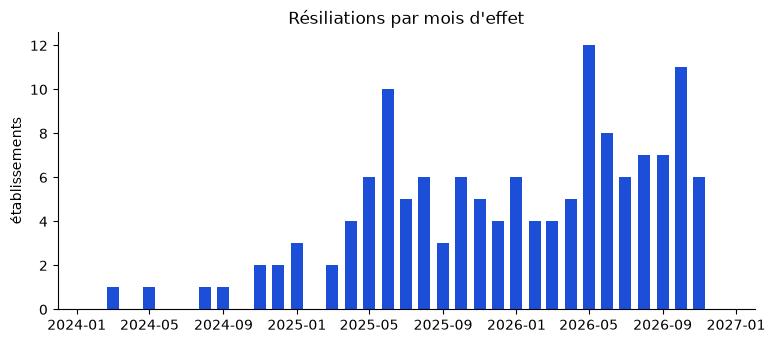

In [3]:
fig, ax = plt.subplots()
r = df.groupby("mois").resilie_mois_suivant.sum()
ax.bar(r.index + pd.offsets.MonthBegin(1), r.values, width=20, color=BLEU)
ax.set_title("Résiliations par mois d'effet"); ax.set_ylabel("établissements")
config.enregistrer_figure(fig, "EDA01_resiliations_par_mois")
plt.show()

In [4]:
def taux(col):
    t = df.groupby(col).resilie_mois_suivant.agg(lignes="count", resiliations="sum", taux_mensuel="mean")
    return t.sort_values("taux_mensuel", ascending=False)

for col in ["formule", "type_etablissement", "nom_canal", "periodicite_facturation", "region"]:
    t = taux(col)
    config.enregistrer_table(t, f"EDA01_taux_resiliation_{col}")
    display(t)

,lignes,resiliations,taux_mensuel
formule,,,
Essentiel,1664,76,0.046
Commande,1674,44,0.026
Pro,828,18,0.022


,lignes,resiliations,taux_mensuel
type_etablissement,,,
fast_food,610,23,0.038
restaurant,992,37,0.037
salon_de_the,680,24,0.035
cafe,1884,54,0.029


,lignes,resiliations,taux_mensuel
nom_canal,,,
Publicité TikTok,477,22,0.046
Publicité Facebook / Instagram,1156,39,0.034
Prospection terrain,1659,51,0.031
Parrainage,503,15,0.030
Salons professionnels,371,11,0.030


,lignes,resiliations,taux_mensuel
periodicite_facturation,,,
mensuelle,3019,112,0.037
annuelle,1147,26,0.023


,lignes,resiliations,taux_mensuel
region,,,
Nord-Est,205,9,0.044
Grand Tunis,2760,95,0.034
Centre-Est,1201,34,0.028


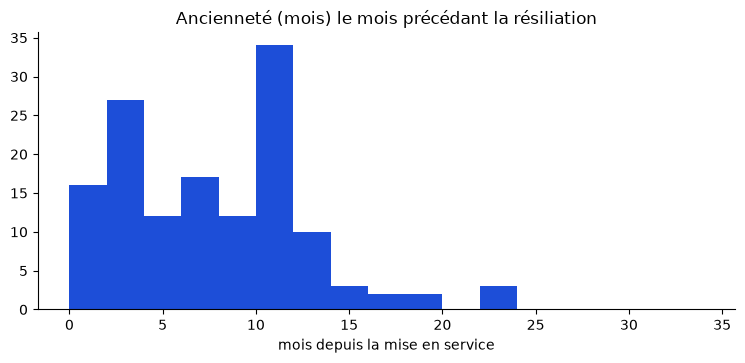

Médiane : 7 mois ; 46% des résiliations avant 7 mois d'ancienneté


In [5]:
fig, ax = plt.subplots()
a = df[df.resilie_mois_suivant == 1].anciennete_mois
ax.hist(a, bins=range(0, 36, 2), color=BLEU)
ax.set_title("Ancienneté (mois) le mois précédant la résiliation"); ax.set_xlabel("mois depuis la mise en service")
config.enregistrer_figure(fig, "EDA01_anciennete_resiliation")
plt.show()
print(f"Médiane : {a.median():.0f} mois ; {(a <= 6).mean():.0%} des résiliations avant 7 mois d'ancienneté")

In [6]:
motifs = chargement.lire("""
    select motif_resiliation, count(*) as resiliations from marts.dim_etablissement
    where date_resiliation is not null group by 1 order by 2 desc""")
motifs

,motif_resiliation,resiliations
0,peu_utilise_par_les_clients,57
1,prix_trop_eleve,32
2,sans_motif,20
3,fermeture_etablissement,13
4,changement_proprietaire,10
5,passage_concurrent,6


**Lecture.** L'histogramme montre un pic de résiliations vers 10 à 12 mois d'ancienneté. Hypothèse à vérifier en T7.2 : la fin du premier engagement annuel. Le motif principal déclaré est « peu utilisé par les clients ». C'est un premier indice : l'usage du menu doit être une variable forte du modèle. Le motif « prix trop élevé » suggère de regarder aussi la formule et le montant facturé.

## 3. Les signaux avant une résiliation

On compare la moyenne de chaque variable entre les lignes suivies d'une résiliation et les autres. Le rapport vaut plus de 1 quand la variable est plus haute avant une résiliation.

In [7]:
VARS = ["sessions_table_jour_3m", "sessions_table_jour_1m", "tendance_usage", "taux_commande_3m",
        "tickets_3m", "satisfaction_6m", "part_factures_retard_6m", "anciennete_mois", "mrr_ht", "nb_tables"]
d = df.copy()
d["tendance_usage"] = np.log(d["tendance_usage"])
moy = d.groupby("resilie_mois_suivant")[VARS].mean().T
moy.columns = ["sans résiliation", "avant résiliation"]
moy["rapport"] = moy["avant résiliation"] / moy["sans résiliation"]
moy = moy.sort_values("rapport")
config.enregistrer_table(moy, "EDA01_signaux_avant_resiliation")
moy

,sans résiliation,avant résiliation,rapport
sessions_table_jour_1m,0.143,0.105,0.733
tendance_usage,1.261,0.947,0.751
sessions_table_jour_3m,0.131,0.108,0.829
mrr_ht,32.143,27.246,0.848
anciennete_mois,7.901,7.413,0.938
nb_tables,17.830,17.058,0.957
satisfaction_6m,3.990,3.860,0.967
taux_commande_3m,0.624,0.617,0.988
tickets_3m,0.552,0.855,1.548
part_factures_retard_6m,0.071,0.182,2.555


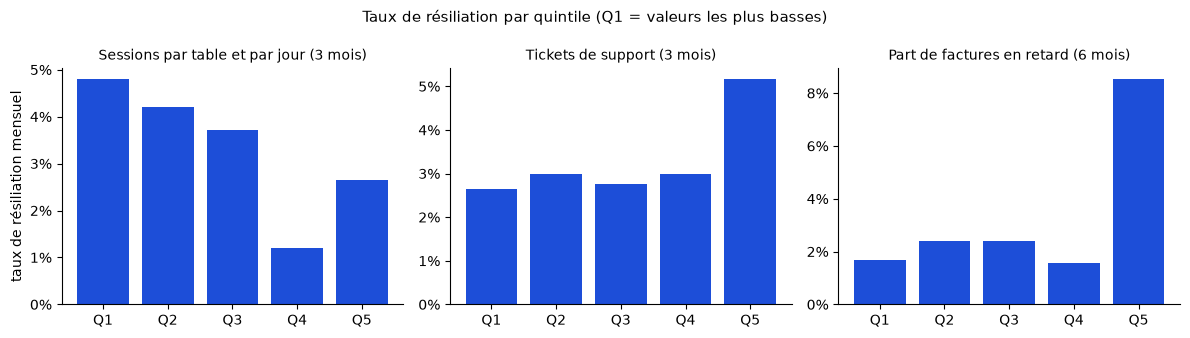

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (col, titre) in zip(axes, [("sessions_table_jour_3m", "Sessions par table et par jour (3 mois)"),
                                   ("tickets_3m", "Tickets de support (3 mois)"),
                                   ("part_factures_retard_6m", "Part de factures en retard (6 mois)")]):
    q = pd.qcut(df[col].rank(method="first"), 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
    t = df.groupby(q, observed=True).resilie_mois_suivant.mean()
    ax.bar(t.index.astype(str), t.values, color=BLEU); ax.set_title(titre, fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("taux de résiliation mensuel")
plt.suptitle("Taux de résiliation par quintile (Q1 = valeurs les plus basses)", fontsize=11)
plt.tight_layout(); config.enregistrer_figure(fig, "EDA01_quintiles_signaux"); plt.show()

**Lecture.** Trois familles de signaux ressortent avant une résiliation :
- **un usage du menu plus faible** ;
- **plus de tickets de support** ;
- **plus de factures payées en retard ou impayées.**

À l'inverse, le taux de commande des sessions ne distingue presque pas les deux groupes. La tendance d'usage est affichée en logarithme : une valeur négative signale une baisse.

Les quintiles montrent que ces relations ne sont pas linéaires :
- tickets et retards de paiement agissent comme un **seuil** : seul le quintile le plus haut (Q5) se détache ;
- l'usage baisse le risque de Q1 à Q4, puis Q5 remonte un peu.

Une régression logistique sur les valeurs brutes captera mal ces formes. D'où deux pistes pour T7.2 : des indicateurs de seuil dans la régression logistique, et la forêt aléatoire, qui gère ces formes sans réglage. Ces variables correspondent aux facteurs prévus dans le cahier des charges (EF-10) : usage, tendance d'usage, tickets, retards de paiement, formule, canal, ancienneté.

## 4. Découpage pour le modèle de résiliation (T7.2)

Le jalon J8 demande une AUC d'au moins 0,75 sur 2026. Le découpage est donc temporel :
- **entraînement** sur les résiliations de 2024 et 2025 ;
- **test** sur celles de 2026, que le modèle n'a jamais vues.

Un découpage aléatoire serait plus optimiste et moins honnête.

In [9]:
df["jeu"] = temporal_split.jeu(df.mois)
df.groupby("jeu").agg(lignes=("resilie_mois_suivant", "count"), resiliations=("resilie_mois_suivant", "sum"),
                      etablissements=("etablissement_id", "nunique"))

,lignes,resiliations,etablissements
jeu,,,
entraînement (résiliations 2024-2025),1708,62,207
test (résiliations 2026),2458,76,327


**Point d'attention.** Le jeu de test compte 76 résiliations seulement. L'AUC mesurée aura donc une marge d'incertitude de plusieurs points. La fiche modèle l'estimera par rééchantillonnage (bootstrap), au lieu de donner un chiffre seul.

## 5. Paniers : matière des règles d'association (T7.3, EF-12)

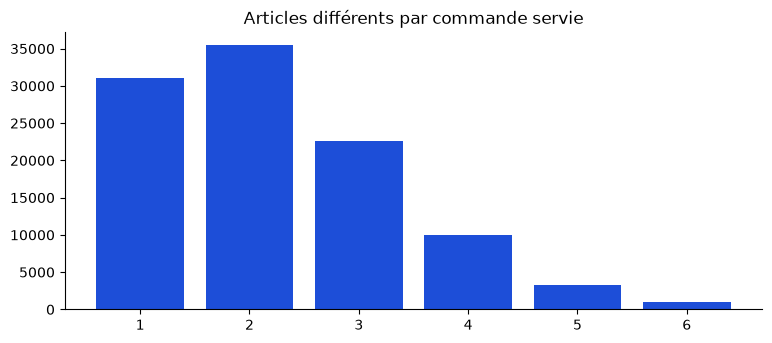

103 385 commandes servies ; 70% contiennent au moins 2 articles différents


In [10]:
paniers = chargement.lire("""
    select l.commande_id, count(distinct l.article_id) as articles
    from marts.fait_ligne_commande l where l.est_servie group by 1""")
t = paniers.articles.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(t.index.astype(str), t.values, color=BLEU); ax.set_title("Articles différents par commande servie")
config.enregistrer_figure(fig, "EDA01_taille_paniers")
plt.show()
print(f"{len(paniers):,} commandes servies ; {(paniers.articles >= 2).mean():.0%} contiennent au moins 2 articles différents".replace(",", " "))

In [11]:
pro = chargement.lire("""
    select e.nom_etablissement, count(distinct l.commande_id) as commandes
    from marts.fait_ligne_commande l join marts.dim_etablissement e using (etablissement_id)
    where l.est_servie and e.formule_actuelle = 'Pro' group by 1 order by 2 desc""")
print(f"{len(pro)} établissements en formule Pro ; commandes servies par établissement : "
      f"médiane {pro.commandes.median():.0f}, minimum {pro.commandes.min()}")

63 établissements en formule Pro ; commandes servies par établissement : médiane 498, minimum 5


**Lecture.** Une majorité de commandes contient plusieurs articles : les règles d'association ont de la matière. Mais chaque établissement a sa propre carte, et les plus petits établissements Pro n'ont que quelques commandes. Les règles seront donc cherchées au niveau des **catégories et des noms de plats**, tous établissements confondus, puis appliquées à la carte de chaque établissement Pro.

## 6. Prix : matière de la sensibilité au prix (T7.3, EF-11)

In [12]:
prix = chargement.lire("""
    select nom_categorie, count(*) filter (where motif_changement <> 'creation') as changements,
           avg((prix_ttc - prix_precedent) / prix_precedent) filter (where motif_changement <> 'creation') as variation_moyenne
    from marts.dim_article group by 1 order by 2 desc""")
config.enregistrer_table(prix, "EDA01_changements_prix_categorie", index=False)
prix

,nom_categorie,changements,variation_moyenne
0,Boissons chaudes,745,0.085
1,Boissons fraîches,603,0.074
2,Jus frais,257,0.067
3,Crêpes et gaufres,245,0.071
4,Viennoiseries,211,0.073
5,Petit-déjeuner,195,0.064
6,Desserts,156,0.072
7,Entrées,126,0.061
8,Plats,122,0.072
9,Grillades,100,0.072


**Lecture.** Il y a des milliers de changements de prix, presque tous des hausses (révisions annuelles). Mais un article d'un établissement se vend peu, comme l'a montré la page TB-8. L'élasticité sera donc estimée **par catégorie**, sur tous les établissements, avec un modèle log-log et un intervalle de confiance. Le cahier des charges le prévoit : élasticité par catégorie, avec intervalle.

## 7. Conclusions pour la suite

| Modèle | Données | Choix retenus |
|---|---|---|
| Risque de résiliation (T7.2) | Jeu mensuel, environ 3 % de positifs | Découpage temporel (test = 2026). Régression logistique puis forêt aléatoire, classes pondérées. AUC avec intervalle par bootstrap. 3 facteurs principaux par établissement |
| Plats recommandés (T7.3) | Paniers à plusieurs articles | Règles d'association (support, confiance, lift) sur les noms de plats, appliquées à la carte de chaque établissement Pro |
| Sensibilité au prix (T7.3) | Changements de prix par catégorie | Régression log-log par catégorie, intervalle de confiance, calendrier en contrôle |

Les essais seront suivis dans MLflow, en mode local. Les résultats retenus iront dans un schéma `ml` de l'entrepôt (T7.4). Suite : `02_data_mining` (règles d'association, sensibilité au prix) et `03_machine_learning` (résiliation).